# 08 — CTU-13 Cross-Scenario Robustness & Generalization (Flow-only)

**Mục tiêu:** đánh giá BOTNET/NORMAL qua các scenario với các feature flow sẵn có; phân tích sự suy giảm khả năng tổng quát hóa. Notebook thay thế Temporal Training gốc vì CTU Parquet hiện tại không cung cấp timestamp và source/destination IP.

**Thực nghiệm chính (confirmatory within this exploratory pilot):** scenario **5 train**, **11 validation** dùng chọn model và threshold; **12 test** chỉ đánh giá sau khi đã khóa model/threshold. Các scenario đã được xem ở Notebook 06–07 nên báo cáo này vẫn là **exploratory**, không phải independent holdout mới.

**Thực nghiệm phụ R1:** ma trận cross-scenario chỉ để **chẩn đoán domain shift**. Việc huấn luyện trên scenario 12 trong R1 không dùng để chọn kết quả chính hoặc tuyên bố generalization lên scenario 12. Không coi UNKNOWN/BACKGROUND là NORMAL. Không dựng graph, không tạo chuỗi thời gian giả.

## 0. Thiết lập môi trường và đường dẫn

In [95]:
from pathlib import Path
import os, re, io, json, zipfile, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
  confusion_matrix, classification_report, roc_auc_score, average_precision_score)
import joblib

SEED=42
SPLITS={'train':5,'validation':11,'test':12}
NUMERIC=['dur','stos','dtos','tot_pkts','tot_bytes','src_bytes']
CATEGORICAL=['proto','dir','state']
FEATURES=NUMERIC+CATEGORICAL
CTU_PATH=os.getenv('CTU_PATH','').strip()  # optional override
FPR_LIMIT=0.10
THRESHOLD_GRID=np.linspace(0.01,0.99,99)
R1_DIAGNOSTIC=True
OUT=Path('/kaggle/working/nids_outputs/08_CTU_CrossScenario_Robustness' if Path('/kaggle/working').exists() else './nids_outputs/08_CTU_CrossScenario_Robustness')
OUT.mkdir(parents=True,exist_ok=True)
print('Output:',OUT.resolve())

Output: /kaggle/working/nids_outputs/08_CTU_CrossScenario_Robustness


## 1. Đọc dữ liệu CTU và kiểm tra schema

In [96]:
PREFERRED=Path('/kaggle/input/datasets/chienvoo/nids-se-at-cnn-data/ctu-13-dataset')
def discover_source():
    if CTU_PATH:
        p=Path(CTU_PATH)
        if p.is_dir():return 'directory',p
        if p.is_file() and p.suffix.lower()=='.zip':return 'zip',p
        raise FileNotFoundError(f'CTU_PATH missing/not directory/ZIP: {p}')
    if PREFERRED.is_dir() and list(PREFERRED.glob('*.binetflow.parquet')):
        return 'directory',PREFERRED
    root=Path('/kaggle/input') if Path('/kaggle/input').is_dir() else Path('/mnt/data')
    dirs=sorted({p.parent for p in root.rglob('*.binetflow.parquet')})
    if len(dirs)==1:return 'directory',dirs[0]
    if len(dirs)>1:raise RuntimeError(f'Multiple CTU sources: {dirs}. Set CTU_PATH.')
    zips=[]
    for zpath in root.rglob('*.zip'):
        try:
            with zipfile.ZipFile(zpath) as z:
                hits=[x for x in z.namelist() if re.search(r'(^|/)\d+-[^/]+\.binetflow\.parquet$',x)]
                if len(hits)>=3:zips.append(zpath)
        except (OSError, zipfile.BadZipFile):continue
    if len(zips)==1:return 'zip',zips[0]
    raise FileNotFoundError(f'Could not uniquely locate CTU Parquet: directories={dirs}, zips={zips}. Specify CTU_PATH.')
source_type,source_path=discover_source()
if source_type=='directory':items=[(q.name,q) for q in source_path.rglob('*.binetflow.parquet')]
else:
    with zipfile.ZipFile(source_path) as z:
        items=[(Path(name).name,name) for name in z.namelist() if name.endswith('.binetflow.parquet')]
files={}
for name,location in items:
    m=re.match(r'^(\d+)-',name)
    if not m:continue
    sid=int(m.group(1))
    if sid in files:raise ValueError(f'Duplicate scenario ID {sid}')
    files[sid]=location
assert set(SPLITS.values()).issubset(files),f'Scenarios missing: {set(SPLITS.values())-set(files)}'
def read_scenario(sid):
    if source_type=='directory':df=pd.read_parquet(files[sid])
    else:
        with zipfile.ZipFile(source_path) as z:df=pd.read_parquet(io.BytesIO(z.read(files[sid])))
    df.columns=df.columns.astype(str).str.strip()
    return df
frames={name:read_scenario(sid) for name,sid in SPLITS.items()}
cols={split:set(df.columns) for split,df in frames.items()}
assert all(v==cols['train'] for v in cols.values()),'Scenario schemas differ; investigate.'
assert set(FEATURES+['label']).issubset(cols['train']),f'Missing features: {set(FEATURES+['label'])-cols["train"]}'
normalized={re.sub('[^a-z0-9]','',c.lower()):c for c in cols['train']}
source_ip=next((normalized[k] for k in ('srcaddr','srcip','sourceip') if k in normalized),None)
dest_ip=next((normalized[k] for k in ('dstaddr','dstip','destinationip') if k in normalized),None)
tstamp=next((normalized[k] for k in ('starttime','timestamp','flowstarttime','time') if k in normalized),None)
readiness={'source_ip':source_ip,'dest_ip':dest_ip,'timestamp':tstamp,
           'graph_feasible':bool(source_ip and dest_ip),
           'beacon_feasible':bool(source_ip and dest_ip and tstamp)}
(OUT/'schema_readiness.json').write_text(json.dumps(readiness,indent=2))
print('CTU source:',source_path)
print('Columns:',sorted(cols['train']))
print('Rows:',{s:len(df) for s,df in frames.items()})
print('Graph/time feasibility:',readiness)
if not readiness['graph_feasible']:print('NO HOST GRAPH OR BEACONING: missing endpoints; this notebook performs flow drift diagnostics only.')

CTU source: /kaggle/input/datasets/chienvoo/nids-se-at-cnn-data/ctu-13-dataset
Columns: ['Family', 'dir', 'dtos', 'dur', 'label', 'proto', 'src_bytes', 'state', 'stos', 'tot_bytes', 'tot_pkts']
Rows: {'train': 92900, 'validation': 72359, 'test': 218917}
Graph/time feasibility: {'source_ip': None, 'dest_ip': None, 'timestamp': None, 'graph_feasible': False, 'beacon_feasible': False}
NO HOST GRAPH OR BEACONING: missing endpoints; this notebook performs flow drift diagnostics only.


## 2. Audit nhãn và tạo các tập flow có nhãn xác định

In [97]:
def label_group(raw):
    if pd.isna(raw):return 'UNKNOWN'
    s=str(raw).strip().lower()
    if s.startswith('flow='):s=s[5:]
    if s.startswith('from-botnet'):return 'BOTNET'
    if s.startswith('from-normal') or s.startswith('normal-'):return 'NORMAL'
    return 'UNKNOWN'
rows=[];X={};Y={}
for split,df in frames.items():
    group=df['label'].map(label_group)
    counts=group.value_counts()
    rows.append({'split':split,'scenario':SPLITS[split], 'total':len(df),
        'normal':int(counts.get('NORMAL',0)),'botnet':int(counts.get('BOTNET',0)),
        'unknown':int(counts.get('UNKNOWN',0)),
        'botnet_prior_known':float(counts.get('BOTNET',0)/max(1,counts.get('NORMAL',0)+counts.get('BOTNET',0)))})
    sel=group.isin(['NORMAL','BOTNET'])
    data=df.loc[sel,FEATURES].copy()
    for c in NUMERIC:data[c]=pd.to_numeric(data[c],errors='coerce').replace([np.inf,-np.inf],np.nan)
    for c in CATEGORICAL:data[c]=data[c].astype('object').where(data[c].notna(),np.nan)
    X[split]=data; Y[split]=(group.loc[sel]=='BOTNET').astype(int).to_numpy()
lab=pd.DataFrame(rows)
display(lab);lab.to_csv(OUT/'scenario_label_audit.csv',index=False)
assert len(np.unique(Y['train']))==2 and len(np.unique(Y['validation']))==2 and len(np.unique(Y['test']))==2
print('UNKNOWN excluded from supervised metrics, not treated as NORMAL.')
assert all(X[s].columns.tolist()==FEATURES for s in SPLITS)


,split,scenario,total,normal,botnet,unknown,botnet_prior_known
0,train,5,92900,4467,880,87553,0.164578
1,validation,11,72359,1507,786,70066,0.342782
2,test,12,218917,6885,2000,210032,0.225098


UNKNOWN excluded from supervised metrics, not treated as NORMAL.


## 3. Preprocessing chỉ fit trên train và định nghĩa mô hình

- RF: median imputation + one-hot.
- HGB, MLP: median imputation + StandardScaler + one-hot (dense).
- Fit pipeline **chỉ trên train** để không rò rỉ thống kê validation/test.
- Không dùng scenario ID hay label/family làm feature.


In [98]:
def one_hot():
    try:return OneHotEncoder(handle_unknown='ignore',sparse_output=False)
    except TypeError:return OneHotEncoder(handle_unknown='ignore',sparse=False)

def prepare_model(name,seed=SEED):
    if name=='RandomForest':
        num=Pipeline([('imputer',SimpleImputer(strategy='median'))])
        clf=RandomForestClassifier(n_estimators=120,max_depth=18,min_samples_leaf=3,
            class_weight='balanced_subsample',n_jobs=-1,random_state=seed)
    elif name=='HistGradientBoosting':
        num=Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())])
        clf=HistGradientBoostingClassifier(max_iter=130,max_leaf_nodes=15,max_depth=6,
            l2_regularization=2.0,early_stopping=False,random_state=seed)
    elif name=='MLP':
        num=Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())])
        clf=MLPClassifier(hidden_layer_sizes=(64,32),alpha=0.005,batch_size=256,
            learning_rate_init=0.001,max_iter=120,early_stopping=True,
            n_iter_no_change=12,random_state=seed)
    else:raise ValueError(name)
    pre=ColumnTransformer([
      ('num',num,NUMERIC),
      ('cat',Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),
                        ('onehot',one_hot())]),CATEGORICAL)],remainder='drop',sparse_threshold=0)
    return Pipeline([('preprocess',pre),('classifier',clf)])

def metrics(y,pred,score=None):
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    z={'accuracy':float(accuracy_score(y,pred)),
       'botnet_precision':float(precision_score(y,pred,zero_division=0)),
       'botnet_recall':float(recall_score(y,pred,zero_division=0)),
       'botnet_f1':float(f1_score(y,pred,zero_division=0)),
       'macro_f1':float(f1_score(y,pred,average='macro',zero_division=0)),
       'fpr':float(fp/(fp+tn)) if (tn+fp)>0 else None,
       'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp)}
    if score is not None and len(np.unique(y))==2:
        z['roc_auc']=float(roc_auc_score(y,score))
        z['average_precision']=float(average_precision_score(y,score))
    return z

assert not set(['label','family','scenario_id']).intersection(FEATURES)
print('Feature list:',FEATURES)

Feature list: ['dur', 'stos', 'dtos', 'tot_pkts', 'tot_bytes', 'src_bytes', 'proto', 'dir', 'state']


## 4. R2 — So sánh RF, HistGradientBoosting và MLP trên validation scenario 11

In [99]:
model_names=['RandomForest','HistGradientBoosting','MLP']
models={}; val_rows=[]; val_scores={}; fit_seconds={}
for name in model_names:
    print('Fitting',name,flush=True)
    model=prepare_model(name)
    tic=time.perf_counter();model.fit(X['train'],Y['train']);fit_seconds[name]=time.perf_counter()-tic
    p=model.predict_proba(X['validation'])[:,1]
    assert len(p)==len(Y['validation']) and np.isfinite(p).all()
    models[name]=model;val_scores[name]=p
    row={'model':name,'threshold':0.5,'fit_seconds':fit_seconds[name],
         **metrics(Y['validation'],(p>=0.5).astype(int),p)}
    val_rows.append(row)
    print(name,'validation Botnet F1:',round(row['botnet_f1'],4),'ROC-AUC:',round(row['roc_auc'],4))
val_default=pd.DataFrame(val_rows)
display(val_default);val_default.to_csv(OUT/'validation_models_default_threshold.csv',index=False)

Fitting RandomForest
RandomForest validation Botnet F1: 0.0039 ROC-AUC: 0.503
Fitting HistGradientBoosting
HistGradientBoosting validation Botnet F1: 0.0076 ROC-AUC: 0.6409
Fitting MLP
MLP validation Botnet F1: 0.0 ROC-AUC: 0.5373


,model,threshold,fit_seconds,accuracy,botnet_precision,botnet_recall,botnet_f1,macro_f1,fpr,TN,FP,FN,TP,roc_auc,average_precision
0,RandomForest,0.5,0.528468,0.338421,0.004071,0.003817,0.003940,0.254337,0.487060,773,734,783,3,0.503027,0.332202
1,HistGradientBoosting,0.5,0.332188,0.656782,0.428571,0.003817,0.007566,0.400039,0.002654,1503,4,783,3,0.640850,0.551485
2,MLP,0.5,0.538889,0.657218,0.000000,0.000000,0.000000,0.396579,0.000000,1507,0,786,0,0.537341,0.383366


## 5. Chọn model và threshold hoàn toàn bằng validation

Chọn cấu hình tối đa hóa BOTNET F1 với điều kiện FPR ≤ 10% trên validation. Nếu không có ngưỡng thỏa ràng buộc, ghi nhận và dùng BOTNET F1 tốt nhất *không ràng buộc*. Tie-break: FPR thấp hơn, Average Precision cao hơn, threshold cao hơn. **Không đọc test trong bước này.**

In [100]:
grid_rows=[]
for name,p in val_scores.items():
    ap=float(average_precision_score(Y['validation'],p))
    for t in THRESHOLD_GRID:
        grid_rows.append({'model':name,'threshold':float(t),'average_precision':ap,
            **metrics(Y['validation'],(p>=t).astype(int))})
val_grid=pd.DataFrame(grid_rows)
val_grid.to_csv(OUT/'validation_model_threshold_grid.csv',index=False)
valid=val_grid[val_grid.fpr<=FPR_LIMIT].copy()
constraint='validation FPR <= 10%'
if valid.empty:
    valid=val_grid.copy();constraint='infeasible FPR bound: fallback to unconstrained Botnet F1'
    warnings.warn(constraint)
selected=valid.sort_values(['botnet_f1','fpr','average_precision','threshold'],
    ascending=[False,True,False,False]).iloc[0]
selected_name=str(selected['model']);selected_threshold=float(selected['threshold'])
selection={'model':selected_name,'threshold':selected_threshold,'constraint':constraint,
 'criterion':'max validation botnet F1, constrained by FPR, deterministic tie breaks',
 'validation_metrics':{k:(float(v) if isinstance(v,(float,np.floating)) else int(v) if isinstance(v,(int,np.integer)) else v) for k,v in selected.to_dict().items()},
 'test_used_for_selection':False}
(OUT/'validation_selection.json').write_text(json.dumps(selection,indent=2,ensure_ascii=False))
print('LOCKED before test:',selected_name,'threshold=',selected_threshold)
display(pd.DataFrame([selection['validation_metrics']]))

LOCKED before test: HistGradientBoosting threshold= 0.02


,model,threshold,average_precision,accuracy,botnet_precision,botnet_recall,botnet_f1,macro_f1,fpr,TN,FP,FN,TP
0,HistGradientBoosting,0.02,0.551485,0.762756,0.781395,0.427481,0.552632,0.695604,0.062376,1413,94,450,336


## 6. Đánh giá test scenario 12 một lần với cấu hình đã khóa

LOCKED TEST RESULTS


,model,threshold,accuracy,botnet_precision,botnet_recall,botnet_f1,macro_f1,fpr,TN,FP,FN,TP,roc_auc,average_precision
0,HistGradientBoosting,0.02,0.824086,0.574497,0.8425,0.683154,0.780698,0.181264,5637,1248,315,1685,0.887411,0.657898


,precision,recall,f1-score,support
NORMAL,0.947077,0.818736,0.878243,6885.000000
BOTNET,0.574497,0.842500,0.683154,2000.000000
accuracy,0.824086,0.824086,0.824086,0.824086
macro avg,0.760787,0.830618,0.780698,8885.000000
weighted avg,0.863210,0.824086,0.834328,8885.000000


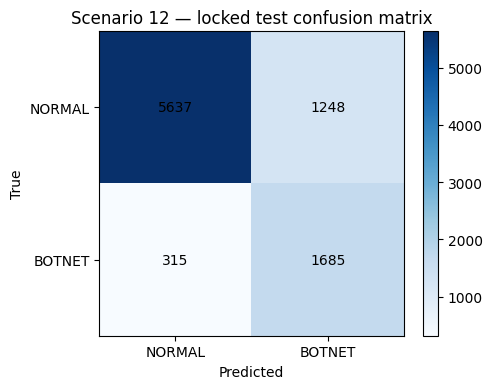

['/kaggle/working/nids_outputs/08_CTU_CrossScenario_Robustness/selected_flow_model.joblib']

In [101]:
winner=models[selected_name]
ptest=winner.predict_proba(X['test'])[:,1]
ytest=Y['test'];yhat=(ptest>=selected_threshold).astype(int)
final_metrics=metrics(ytest,yhat,ptest)
print('LOCKED TEST RESULTS')
display(pd.DataFrame([{'model':selected_name,'threshold':selected_threshold,**final_metrics}]))
report=classification_report(ytest,yhat,labels=[0,1],target_names=['NORMAL','BOTNET'],
                             output_dict=True,zero_division=0)
report_df=pd.DataFrame(report).T
report_df.to_csv(OUT/'test_classification_report.csv')
display(report_df)
cm=confusion_matrix(ytest,yhat,labels=[0,1])
pd.DataFrame(cm,index=['true_NORMAL','true_BOTNET'],columns=['pred_NORMAL','pred_BOTNET']).to_csv(OUT/'test_confusion_matrix.csv')
fig,ax=plt.subplots(figsize=(5,4));im=ax.imshow(cm,cmap='Blues')
for (i,j),v in np.ndenumerate(cm):ax.text(j,i,str(v),ha='center',va='center')
ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['NORMAL','BOTNET'],yticklabels=['NORMAL','BOTNET'],
       xlabel='Predicted',ylabel='True',title='Scenario 12 — locked test confusion matrix')
plt.colorbar(im,ax=ax);plt.tight_layout();plt.savefig(OUT/'test_confusion_matrix.png',dpi=160);plt.show()
(OUT/'final_test_metrics.json').write_text(json.dumps({'model':selected_name,'threshold':selected_threshold,
  'metrics':final_metrics,'scenario':12,'test_is_exploratory':True},indent=2))
joblib.dump(winner,OUT/'selected_flow_model.joblib')

## 7. R1 — Cross-scenario transfer matrix (diagnostic only)

**Cảnh báo phương pháp:** Đây là thí nghiệm chẩn đoán **sau khi khóa kết quả chính**. Từng scenario lần lượt đóng vai trò nguồn huấn luyện và tập đánh giá; mô hình huấn luyện từ scenario 12 **không được sử dụng** để điều chỉnh cấu hình chính hoặc tuyên bố kết quả independent test. Giữ RF cố định (không search hyperparameters). Giá trị trong đường chéo là **in-sample**, không phải generalization và phải được gắn nhãn tương ứng.


,train_scenario,eval_scenario,evaluation_type,botnet_recall,botnet_f1,fpr,roc_auc
0,5,5,in-sample (not generalization),0.932955,0.943678,0.008731,0.998388
1,5,11,cross-scenario exploratory,0.003817,0.003940,0.487060,0.503027
2,5,12,cross-scenario exploratory,0.049000,0.085927,0.026580,0.897155
3,11,5,cross-scenario exploratory,0.001136,0.002262,0.000672,0.717878
4,11,11,in-sample (not generalization),0.987277,0.993598,0.000000,0.999996
5,11,12,cross-scenario exploratory,0.115000,0.205817,0.000726,0.882212
6,12,5,cross-scenario exploratory,0.511364,0.642857,0.015670,0.871617
7,12,11,cross-scenario exploratory,0.982188,0.940890,0.055076,0.988214
8,12,12,in-sample (not generalization),0.951500,0.965010,0.005955,0.998869


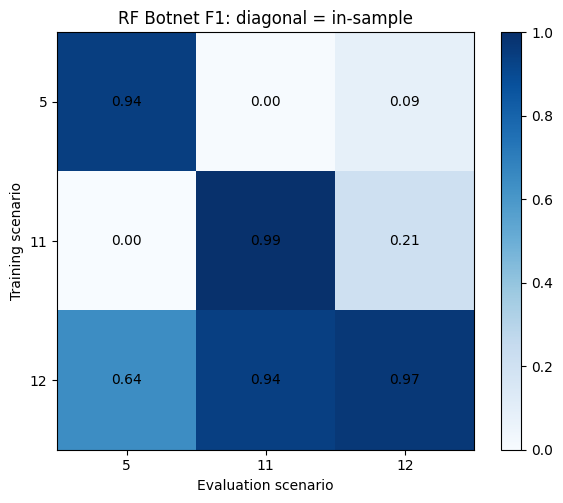

In [102]:
transfer=[]
if R1_DIAGNOSTIC:
    for source in SPLITS:
        diagnostic=prepare_model('RandomForest',seed=SEED)
        diagnostic.fit(X[source],Y[source])
        for destination in SPLITS:
            score=diagnostic.predict_proba(X[destination])[:,1]
            met=metrics(Y[destination],(score>=0.5).astype(int),score)
            transfer.append({'train_scenario':SPLITS[source],
                'eval_scenario':SPLITS[destination],
                'evaluation_type':'in-sample (not generalization)' if source==destination else 'cross-scenario exploratory',
                **met})
    transfer_df=pd.DataFrame(transfer)
    transfer_df.to_csv(OUT/'cross_scenario_transfer_matrix.csv',index=False)
    display(transfer_df[['train_scenario','eval_scenario','evaluation_type','botnet_recall','botnet_f1','fpr','roc_auc']])
    pvt=transfer_df.pivot(index='train_scenario',columns='eval_scenario',values='botnet_f1')
    fig,ax=plt.subplots(figsize=(6,5));im=ax.imshow(pvt.values,vmin=0,vmax=1,cmap='Blues')
    for (i,j),v in np.ndenumerate(pvt.values):ax.text(j,i,f'{v:.2f}',ha='center',va='center')
    ax.set(xticks=range(len(pvt.columns)),yticks=range(len(pvt.index)),
      xticklabels=pvt.columns,yticklabels=pvt.index, xlabel='Evaluation scenario',
      ylabel='Training scenario',title='RF Botnet F1: diagonal = in-sample')
    plt.colorbar(im,ax=ax);plt.tight_layout();plt.savefig(OUT/'cross_scenario_transfer_matrix.png',dpi=160);plt.show()
else:print('R1_DIAGNOSTIC=False; skip secondary transfer matrix')

## 8. R3 — Lỗi của mô hình cuối và đặc trưng ngoài phân phối

Chỉ dùng score test để mô tả sai sót **sau khi đã khóa model**, không dùng để thay model, threshold hoặc lựa chọn feature. Đối với categorical, đo tỷ lệ giá trị chưa thấy trên train; đối với numeric, so sánh median và phân vị 10/90. Tránh khẳng định drift là nguyên nhân nhân quả.

In [103]:
err=pd.DataFrame({'actual':ytest,'predicted':yhat,'prob_botnet':ptest})
err['result']=np.select([(err.actual==1)&(err.predicted==0),
 (err.actual==0)&(err.predicted==1),(err.actual==1)&(err.predicted==1)],
 ['FN_BOTNET','FP_BOTNET','TP_BOTNET'],default='TN_NORMAL')
err.to_csv(OUT/'test_prediction_error_audit.csv',index=False)
print('Error counts:',err.result.value_counts().to_dict())
feat_audit=[]
for c in NUMERIC:
    a=pd.to_numeric(X['train'][c],errors='coerce').to_numpy(dtype=float)
    b=pd.to_numeric(X['validation'][c],errors='coerce').to_numpy(dtype=float)
    d=pd.to_numeric(X['test'][c],errors='coerce').to_numpy(dtype=float)
    def stat(v,q):return float(np.nanquantile(v,q)) if np.isfinite(v).any() else None
    feat_audit.append({'feature':c,'kind':'numeric','train_median':stat(a,.5),
      'validation_median':stat(b,.5),'test_median':stat(d,.5),
      'train_p10':stat(a,.1),'train_p90':stat(a,.9),
      'test_p10':stat(d,.1),'test_p90':stat(d,.9)})
for c in CATEGORICAL:
    seen=set(X['train'][c].dropna().astype(str))
    for split in ('validation','test'):
        vals=X[split][c].dropna().astype(str)
        feat_audit.append({'feature':c,'kind':'unseen_category_rate',
          'split':split,'unseen_rate':float((~vals.isin(seen)).mean()) if len(vals) else None})
feat_df=pd.DataFrame(feat_audit);feat_df.to_csv(OUT/'feature_generalization_audit.csv',index=False)
display(feat_df)
# Compare probability separation, not just binary accuracy
score_by_class=pd.DataFrame({'label':ytest,'score':ptest}).groupby('label').score.agg(['count','mean','median','std'])
score_by_class.to_csv(OUT/'test_probability_by_class.csv')
display(score_by_class)

Error counts: {'TN_NORMAL': 5637, 'TP_BOTNET': 1685, 'FP_BOTNET': 1248, 'FN_BOTNET': 315}


,feature,kind,train_median,validation_median,test_median,train_p10,train_p90,test_p10,test_p90,split,unseen_rate
0,dur,numeric,0.021872,0.001028,0.035822,0.000248,30.990405,0.00027,80.335315,NaN,NaN
1,stos,numeric,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,NaN,NaN
2,dtos,numeric,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,NaN,NaN
3,tot_pkts,numeric,2.000000,2.000000,2.000000,2.000000,31.000000,2.00000,30.000000,NaN,NaN
4,tot_bytes,numeric,366.000000,400.000000,412.000000,206.000000,11527.800000,208.00000,10351.200000,NaN,NaN
5,src_bytes,numeric,88.000000,78.000000,148.000000,73.000000,2590.000000,74.00000,1874.600000,NaN,NaN
6,proto,unseen_category_rate,NaN,NaN,NaN,NaN,NaN,NaN,NaN,validation,0.750981
7,proto,unseen_category_rate,NaN,NaN,NaN,NaN,NaN,NaN,NaN,test,0.001688
8,dir,unseen_category_rate,NaN,NaN,NaN,NaN,NaN,NaN,NaN,validation,0.000000
9,dir,unseen_category_rate,NaN,NaN,NaN,NaN,NaN,NaN,NaN,test,0.000000


,count,mean,median,std
label,,,,
0,6885,0.026813,0.004740,0.092520
1,2000,0.180696,0.093217,0.226135


## 9. Manifest, limitations và hướng chuyển sang Notebook 09

In [104]:
manifest={
 'notebook':'08_CTU_CrossScenario_Robustness_Generalization',
 'data_source':str(source_path),'scenarios':SPLITS,
 'features':FEATURES,'labels':'known NORMAL and BOTNET only; BACKGROUND excluded',
 'graph_feasible':readiness['graph_feasible'],'beacon_feasible':readiness['beacon_feasible'],
 'selected_model':selected_name,'selected_threshold':selected_threshold,
 'selection_split':'scenario 11 validation only','evaluation_split':'scenario 12 test (previously inspected exploratory)',
 'selection_criterion':constraint,'r1_transfer_matrix_is_diagnostic_only':True,
 'comparability':'CTU binary BOTNET/NORMAL; not directly comparable to CIC 15-class classifier',
 'artifacts':sorted(p.name for p in OUT.iterdir() if p.is_file())}
(OUT/'experiment_manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False))
print('Saved files:',len(list(OUT.iterdir())),'to',OUT)
print('CONCLUSION: report both Botnet Recall/F1 and FPR; high Accuracy alone is not evidence of effective detection.')

Saved files: 16 to /kaggle/working/nids_outputs/08_CTU_CrossScenario_Robustness
CONCLUSION: report both Botnet Recall/F1 and FPR; high Accuracy alone is not evidence of effective detection.
